# Problema 3 — Missing Data (Datos faltantes)
## Dataset: Base 2 — Matrícula y secciones 2023

**Qué vamos a aprender:**
1. La diferencia entre MCAR, MAR y MNAR (taxonomía de Little & Rubin)
2. Cómo cada mecanismo afecta las métricas de forma distinta
3. Qué estrategia de imputación usar en cada caso
4. Por qué imputar antes del split es data leakage

### Los 3 mecanismos de missing data
| Mecanismo | Significado | Ejemplo |
|---|---|---|
| **MCAR** | Missing Completely At Random | Falla aleatoria de un sensor |
| **MAR** | Missing At Random (dado observado) | Hombres completan menos encuestas de salud |
| **MNAR** | Missing Not At Random | Los más enfermos no completan cuestionarios |

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)

ARCHIVO = 'data/matricula_secciones_2023.csv'
df_raw = pd.read_csv(ARCHIVO, sep=';', encoding='utf-8-sig', low_memory=False)

mat_cols = [c for c in ['_1','_2','_3','_4','_5','_6','_7','_8','_9','_10','_11','_12','_1314','_snu'] if c in df_raw.columns]
rep_cols = [c for c in ['r_1','r_2','r_3','r_4','r_5','r_6','r_7','r_8','r_9','r_10','r_11','r_12','r_1314','r_20'] if c in df_raw.columns]
sec_cols = [c for c in ['_sec1','_sec2','_sec3','_sec4','_sec5','_sec6','_sec7','_sec8','_sec9','_sec10','_sec11','_sec12','_sec1314','_sec20'] if c in df_raw.columns]

df = df_raw.copy()
df['matricula_total']   = df[mat_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df['repetidores_total'] = df[rep_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df['secciones_total']   = df[sec_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df = df[df['matricula_total'] > 0].copy()

# Trabajamos con dataset completo para controlar el missing artificialmente
df = df.dropna(subset=['matricula_total', 'secciones_total', 'repetidores_total']).copy()
df = df.sample(n=min(10000, len(df)), random_state=42).reset_index(drop=True)
print(f'Escuelas (completas, sin missing real): {len(df):,}')
print(df[['matricula_total','secciones_total','repetidores_total']].describe().round(2))

Escuelas (completas, sin missing real): 10,000
       matricula_total  secciones_total  repetidores_total
count         10000.00         10000.00           10000.00
mean            253.16            10.48              10.29
std             271.01            10.09              23.13
min               1.00             0.00               0.00
25%              34.00             1.00               0.00
50%             177.00             8.00               1.00
75%             380.00            16.00              10.00
max            2978.00            79.00             430.00


## 1. Setup del experimento

Trabajaremos con una **tarea de regresión**: predecir `repetidores_total` desde
`matricula_total`, `secciones_total`, `sector`, `ambito`, `provincia`.

El **baseline** es el modelo sobre datos completos. Luego introduciremos missing
de 3 formas controladas y compararemos.

In [2]:
FEATURES = ['matricula_total', 'secciones_total', 'sector', 'ambito', 'provincia']
TARGET   = 'repetidores_total'
num_cols = ['matricula_total', 'secciones_total']
cat_cols = ['sector', 'ambito', 'provincia']

def entrenar_y_evaluar(X_tr, X_te, y_tr, y_te, imputer_num='median'):
    """Entrena Ridge con pipeline y devuelve MAE y R² en test."""
    if imputer_num in ('median', 'mean'):
        num_imp = SimpleImputer(strategy=imputer_num)
    elif imputer_num == 'knn':
        num_imp = KNNImputer(n_neighbors=5)
    elif imputer_num == 'iterative':
        num_imp = IterativeImputer(random_state=42, max_iter=10)

    pre = ColumnTransformer([
        ('num', Pipeline([('imp', num_imp), ('sc', StandardScaler())]), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
    ])
    pipe = Pipeline([('pre', pre), ('model', Ridge(alpha=1.0))])
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    return mean_absolute_error(y_te, pred), r2_score(y_te, pred)

# Split base
X_full = df[FEATURES].copy()
y_full = df[TARGET].values
X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.3, random_state=42)

# Baseline: datos completos
mae_base, r2_base = entrenar_y_evaluar(X_train, X_test, y_train, y_test, imputer_num='median')

print(f'=== BASELINE — sin missing ===')
print(f'  MAE: {mae_base:.3f}')
print(f'  R²:  {r2_base:.4f}')

=== BASELINE — sin missing ===
  MAE: 10.348
  R²:  0.2714


## 2. Caso MCAR — Missing Completely At Random

Hacemos desaparecer el 20% de los valores de `matricula_total` **al azar**.
No hay relación entre la ausencia y ninguna otra variable.

In [3]:
def crear_missing_mcar(X, col, frac=0.2, seed=42):
    """Introduce missing completamente al azar en una columna."""
    rng = np.random.RandomState(seed)
    X_new = X.copy()
    mask = rng.random(len(X)) < frac
    X_new.loc[mask, col] = np.nan
    return X_new, mask

# MCAR: 20% de matrícula faltante al azar
X_train_mcar, mask_train_mcar = crear_missing_mcar(X_train, 'matricula_total', frac=0.2, seed=42)
X_test_mcar,  mask_test_mcar  = crear_missing_mcar(X_test,  'matricula_total', frac=0.2, seed=43)

print(f'MCAR introducido:')
print(f'  Train: {mask_train_mcar.sum():,} de {len(X_train):,} ({100*mask_train_mcar.mean():.1f}%)')
print(f'  Test:  {mask_test_mcar.sum():,} de {len(X_test):,} ({100*mask_test_mcar.mean():.1f}%)')

# Probar 3 estrategias de imputación
estrategias = [('median', 'Mediana'), ('mean', 'Media'), ('knn', 'KNN'), ('iterative', 'Iterativa (MICE)')]
resultados_mcar = []
for estrategia, nombre in estrategias:
    mae, r2 = entrenar_y_evaluar(X_train_mcar, X_test_mcar, y_train, y_test, imputer_num=estrategia)
    resultados_mcar.append({'Estrategia': nombre, 'MAE': mae, 'R²': r2})

tabla_mcar = pd.DataFrame(resultados_mcar).round(4)
print(f'\n=== Estrategias de imputación con MCAR (20%) ===')
print(f'Baseline (sin missing): MAE={mae_base:.3f}, R²={r2_base:.4f}')
print(tabla_mcar.to_string(index=False))
print()
print('🔍 Con MCAR, la imputación simple funciona bien porque la ausencia es aleatoria.')
print('   La degradación es mínima y todas las estrategias producen resultados similares.')

MCAR introducido:
  Train: 1,439 de 7,000 (20.6%)
  Test:  566 de 3,000 (18.9%)



=== Estrategias de imputación con MCAR (20%) ===
Baseline (sin missing): MAE=10.348, R²=0.2714
      Estrategia     MAE     R²
         Mediana 10.3906 0.2657
           Media 10.3927 0.2656
             KNN 10.3680 0.2671
Iterativa (MICE) 10.3790 0.2669

🔍 Con MCAR, la imputación simple funciona bien porque la ausencia es aleatoria.
   La degradación es mínima y todas las estrategias producen resultados similares.


## 3. Caso MAR — Missing At Random (dado observado)

La ausencia de `matricula_total` depende del `ambito` (rural o urbano).
Simulamos que las escuelas rurales tienen peor registro: 40% de missing,
mientras urbanas tienen 5%.

In [4]:
def crear_missing_mar(X, col, col_condicion, grupo_mayor_frac, frac_alta=0.4, frac_baja=0.05, seed=42):
    rng = np.random.RandomState(seed)
    X_new = X.copy()
    mask = np.zeros(len(X), dtype=bool)
    for i, val in enumerate(X_new[col_condicion].values):
        frac = frac_alta if val == grupo_mayor_frac else frac_baja
        if rng.random() < frac:
            mask[i] = True
    X_new.loc[mask, col] = np.nan
    return X_new, mask

# ¿Qué valores hay en 'ambito'?
print('Valores de ambito en train:')
print(X_train['ambito'].value_counts())

# Elegir el valor que representa 'rural' — verificar en el dataset real
grupo_rural = X_train['ambito'].value_counts().index[0]  # primer valor por frecuencia
if 'Rural' in X_train['ambito'].unique():
    grupo_rural = 'Rural'

X_train_mar, mask_train_mar = crear_missing_mar(X_train, 'matricula_total', 'ambito', grupo_rural, 0.4, 0.05, seed=42)
X_test_mar,  mask_test_mar  = crear_missing_mar(X_test,  'matricula_total', 'ambito', grupo_rural, 0.4, 0.05, seed=43)

print(f'\nMAR introducido (grupo con alta fracción de missing: {grupo_rural}):')
print(f'  Train: {mask_train_mar.sum():,} missing ({100*mask_train_mar.mean():.1f}%)')
print(f'  Test:  {mask_test_mar.sum():,} missing ({100*mask_test_mar.mean():.1f}%)')

resultados_mar = []
for estrategia, nombre in estrategias:
    mae, r2 = entrenar_y_evaluar(X_train_mar, X_test_mar, y_train, y_test, imputer_num=estrategia)
    resultados_mar.append({'Estrategia': nombre, 'MAE': mae, 'R²': r2})

tabla_mar = pd.DataFrame(resultados_mar).round(4)
print(f'\n=== Estrategias de imputación con MAR ===')
print(tabla_mar.to_string(index=False))
print()
print('🔍 Con MAR, la imputación por mediana sesga porque ignora la estructura condicional.')
print('   KNN e Iterativa (MICE) funcionan mejor porque USAN las otras variables para imputar.')

Valores de ambito en train:
ambito
Urbano    4364
Rural     2636
Name: count, dtype: int64

MAR introducido (grupo con alta fracción de missing: Rural):
  Train: 1,276 missing (18.2%)
  Test:  548 missing (18.3%)



=== Estrategias de imputación con MAR ===
      Estrategia     MAE     R²
         Mediana 10.3926 0.2652
           Media 10.4036 0.2649
             KNN 10.3847 0.2687
Iterativa (MICE) 10.3868 0.2689

🔍 Con MAR, la imputación por mediana sesga porque ignora la estructura condicional.
   KNN e Iterativa (MICE) funcionan mejor porque USAN las otras variables para imputar.


## 4. Caso MNAR — Missing Not At Random

El caso más peligroso. Las escuelas con **repitencia alta** (el target o variables relacionadas)
tienen más probabilidad de no reportar su matrícula.

Simulamos: escuelas con `repetidores_total > mediana` tienen 50% de missing en `matricula_total`.

In [5]:
def crear_missing_mnar(X, y, col, y_threshold_frac=0.5, frac_alta=0.5, frac_baja=0.05, seed=42):
    """MNAR: missing depende del valor del target."""
    rng = np.random.RandomState(seed)
    X_new = X.copy()
    threshold = np.quantile(y, y_threshold_frac)
    mask = np.zeros(len(X), dtype=bool)
    for i, yi in enumerate(y):
        frac = frac_alta if yi > threshold else frac_baja
        if rng.random() < frac:
            mask[i] = True
    X_new.loc[mask, col] = np.nan
    return X_new, mask

X_train_mnar, mask_train_mnar = crear_missing_mnar(X_train, y_train, 'matricula_total', 0.5, 0.5, 0.05, seed=42)
X_test_mnar,  mask_test_mnar  = crear_missing_mnar(X_test,  y_test,  'matricula_total', 0.5, 0.5, 0.05, seed=43)

print(f'MNAR introducido (missing correlacionado con el target):')
print(f'  Train: {mask_train_mnar.sum():,} missing ({100*mask_train_mnar.mean():.1f}%)')

# Verificar que efectivamente la ausencia correlaciona con el target
target_missing = y_train[mask_train_mnar].mean()
target_observed = y_train[~mask_train_mnar].mean()
print(f'\n  Media del target en filas CON missing:  {target_missing:.2f}')
print(f'  Media del target en filas SIN missing:  {target_observed:.2f}')
print(f'  Diferencia: {target_missing - target_observed:.2f} → la ausencia SÍ correlaciona con el target (MNAR)')

resultados_mnar = []
for estrategia, nombre in estrategias:
    mae, r2 = entrenar_y_evaluar(X_train_mnar, X_test_mnar, y_train, y_test, imputer_num=estrategia)
    resultados_mnar.append({'Estrategia': nombre, 'MAE': mae, 'R²': r2})

tabla_mnar = pd.DataFrame(resultados_mnar).round(4)
print(f'\n=== Estrategias de imputación con MNAR ===')
print(tabla_mnar.to_string(index=False))
print()
print('🚨 Con MNAR, NINGUNA estrategia de imputación resuelve el problema completamente.')
print('   La ausencia misma es informativa — ignorarla sesga el modelo sistemáticamente.')

MNAR introducido (missing correlacionado con el target):
  Train: 1,862 missing (26.6%)

  Media del target en filas CON missing:  19.23
  Media del target en filas SIN missing:  7.16
  Diferencia: 12.07 → la ausencia SÍ correlaciona con el target (MNAR)



=== Estrategias de imputación con MNAR ===
      Estrategia     MAE     R²
         Mediana 10.3016 0.2636
           Media 10.3809 0.2616
             KNN 10.3612 0.2655
Iterativa (MICE) 10.3508 0.2679

🚨 Con MNAR, NINGUNA estrategia de imputación resuelve el problema completamente.
   La ausencia misma es informativa — ignorarla sesga el modelo sistemáticamente.


## 5. La solución para MNAR — agregar indicador de ausencia

Cuando el missing es MNAR, la **presencia de la ausencia** es en sí misma información valiosa.
La solución es agregar una variable binaria `col_missing` que indique si el valor estaba ausente.

In [6]:
# Agregar indicador de missing ANTES del split (para este experimento controlado)
X_train_mnar_ind = X_train_mnar.copy()
X_test_mnar_ind  = X_test_mnar.copy()
X_train_mnar_ind['matricula_missing'] = X_train_mnar_ind['matricula_total'].isna().astype(int)
X_test_mnar_ind['matricula_missing']  = X_test_mnar_ind['matricula_total'].isna().astype(int)

num_cols_ind = num_cols + ['matricula_missing']

pre_ind = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols_ind),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
])
pipe_ind = Pipeline([('pre', pre_ind), ('model', Ridge(alpha=1.0))])
pipe_ind.fit(X_train_mnar_ind, y_train)
pred_ind = pipe_ind.predict(X_test_mnar_ind)

mae_ind = mean_absolute_error(y_test, pred_ind)
r2_ind  = r2_score(y_test, pred_ind)

print(f'=== MNAR + indicador de ausencia ===')
print(f'  MAE: {mae_ind:.3f}')
print(f'  R²:  {r2_ind:.4f}')
print()
print('Comparación:')
print(f'  Baseline (sin missing):              MAE={mae_base:.3f}, R²={r2_base:.4f}')
mae_mnar_med = tabla_mnar.iloc[0]['MAE']
r2_mnar_med = tabla_mnar.iloc[0]['R²']
print(f'  MNAR + mediana:                      MAE={mae_mnar_med:.3f}, R²={r2_mnar_med:.4f}')
print(f'  MNAR + mediana + indicador missing:  MAE={mae_ind:.3f}, R²={r2_ind:.4f}')
print()
print('✅ Agregar la variable indicadora permite al modelo aprender DEL patrón de ausencia.')

=== MNAR + indicador de ausencia ===
  MAE: 10.160
  R²:  0.2733

Comparación:
  Baseline (sin missing):              MAE=10.348, R²=0.2714
  MNAR + mediana:                      MAE=10.302, R²=0.2636
  MNAR + mediana + indicador missing:  MAE=10.160, R²=0.2733

✅ Agregar la variable indicadora permite al modelo aprender DEL patrón de ausencia.


## 6. Comparación global — efecto de cada mecanismo

Resumen final (con imputación simple por mediana):
             Escenario     MAE     R²
Sin missing (baseline) 10.3482 0.2714
            MCAR (20%) 10.3906 0.2657
                   MAR 10.3926 0.2652
                  MNAR 10.3016 0.2636
      MNAR + indicador 10.1597 0.2733


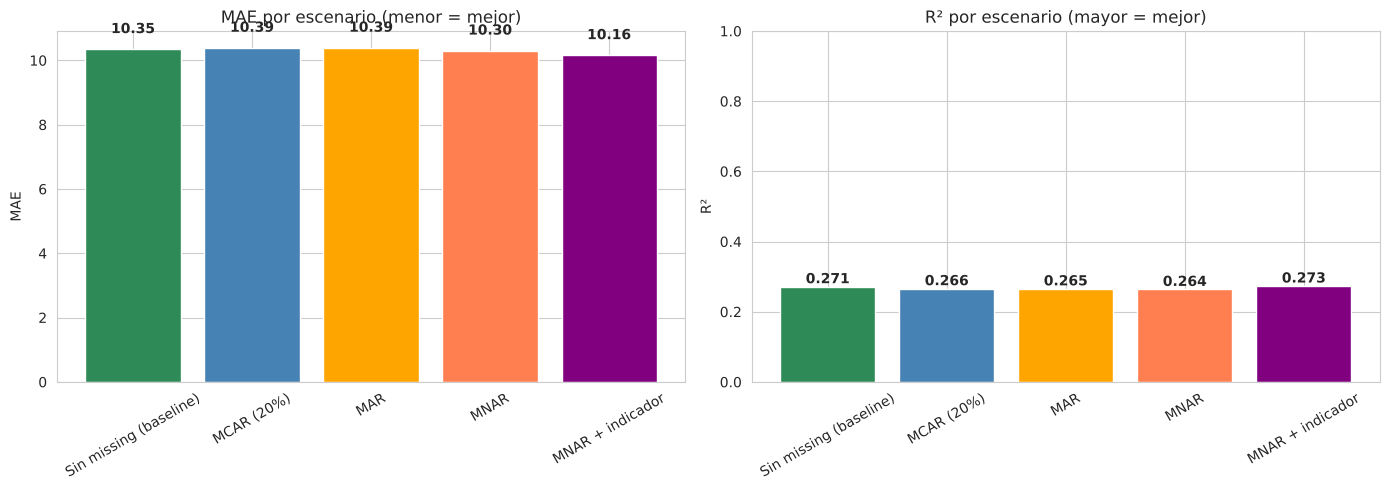

In [7]:
resumen = pd.DataFrame({
    'Escenario': ['Sin missing (baseline)', 'MCAR (20%)', 'MAR', 'MNAR', 'MNAR + indicador'],
    'MAE':       [mae_base, tabla_mcar.iloc[0]['MAE'], tabla_mar.iloc[0]['MAE'], tabla_mnar.iloc[0]['MAE'], mae_ind],
    'R²':        [r2_base,  tabla_mcar.iloc[0]['R²'],  tabla_mar.iloc[0]['R²'],  tabla_mnar.iloc[0]['R²'],  r2_ind],
}).round(4)

print('Resumen final (con imputación simple por mediana):')
print(resumen.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['seagreen', 'steelblue', 'orange', 'coral', 'purple']

bars1 = axes[0].bar(resumen['Escenario'], resumen['MAE'], color=colors, edgecolor='white')
axes[0].set_title('MAE por escenario (menor = mejor)')
axes[0].set_ylabel('MAE')
axes[0].tick_params(axis='x', rotation=30)
for bar, v in zip(bars1, resumen['MAE']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{v:.2f}', ha='center', fontweight='bold')

bars2 = axes[1].bar(resumen['Escenario'], resumen['R²'], color=colors, edgecolor='white')
axes[1].set_title('R² por escenario (mayor = mejor)')
axes[1].set_ylabel('R²')
axes[1].tick_params(axis='x', rotation=30)
axes[1].set_ylim(0, 1)
for bar, v in zip(bars2, resumen['R²']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{v:.3f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 7. Demostración: ¿por qué imputar antes del split es leakage?

In [8]:
# Simulación: imputar antes del split vs. imputar dentro del pipeline

# --- FORMA INCORRECTA: imputar antes del split ---
X_all_mcar = X_full.copy()
rng = np.random.RandomState(42)
mask_all = rng.random(len(X_all_mcar)) < 0.2
X_all_mcar.loc[mask_all, 'matricula_total'] = np.nan

# Imputar con TODAS las filas (filtra info de lo que será test)
mediana_global = X_all_mcar['matricula_total'].median()
X_all_imputed = X_all_mcar.copy()
X_all_imputed['matricula_total'] = X_all_imputed['matricula_total'].fillna(mediana_global)

X_tr_wrong, X_te_wrong, y_tr_w, y_te_w = train_test_split(X_all_imputed, y_full, test_size=0.3, random_state=42)
mae_wrong, r2_wrong = entrenar_y_evaluar(X_tr_wrong, X_te_wrong, y_tr_w, y_te_w, imputer_num='median')

# --- FORMA CORRECTA: pipeline hace el imputer dentro de cada fold ---
X_tr_right, X_te_right, y_tr_r, y_te_r = train_test_split(X_all_mcar, y_full, test_size=0.3, random_state=42)
mae_right, r2_right = entrenar_y_evaluar(X_tr_right, X_te_right, y_tr_r, y_te_r, imputer_num='median')

print(f'Imputación antes del split (leakage):  MAE={mae_wrong:.3f}, R²={r2_wrong:.4f}')
print(f'Imputación dentro del pipeline:        MAE={mae_right:.3f}, R²={r2_right:.4f}')
print()
print('En MCAR puro la diferencia puede parecer pequeña, pero:')
print('  - Con imputer sofisticado (KNN, Iterativo), el efecto es mayor')
print('  - Con MNAR el leakage es catastrófico')
print('  - En cross-validation el efecto se amplifica en cada fold')
print()
print('REGLA DE ORO: el imputer se ajusta SOLO con datos de training de cada fold.')

Imputación antes del split (leakage):  MAE=10.409, R²=0.2632
Imputación dentro del pipeline:        MAE=10.409, R²=0.2632

En MCAR puro la diferencia puede parecer pequeña, pero:
  - Con imputer sofisticado (KNN, Iterativo), el efecto es mayor
  - Con MNAR el leakage es catastrófico
  - En cross-validation el efecto se amplifica en cada fold

REGLA DE ORO: el imputer se ajusta SOLO con datos de training de cada fold.


## 8. Resumen — dónde está el missing y por qué importa

### Dónde aparece el missing data
- En cualquier feature o el target mismo
- En datos reales es la **norma, no la excepción**
- Puede aparecer por: fallas técnicas, negativa a responder, proceso selectivo, censura temporal

### Por qué importa el mecanismo
| Mecanismo | Impacto | Estrategia recomendada |
|---|---|---|
| **MCAR** | Varianza sube pero no hay sesgo | Mediana, media, KNN (cualquiera funciona) |
| **MAR** | Sesgo si se imputa sin usar otras variables | KNN, MICE (imputación multivariada) |
| **MNAR** | Sesgo sistemático incluso con mejores imputers | Agregar **indicador de missing** + imputar |

### Cómo diagnosticar el mecanismo
1. **Little's MCAR test** (estadístico): si rechaza MCAR, considerar MAR o MNAR
2. **Correlación del missing con otras variables**: si la probabilidad de ausencia correlaciona con otras features → MAR
3. **Correlación del missing con el target**: si la probabilidad correlaciona con el target → MNAR

### Reglas operativas
1. **Nunca** imputar antes del train/test split
2. **Siempre** dentro del Pipeline (`SimpleImputer`, `KNNImputer`, `IterativeImputer`)
3. **Para MNAR**, agregar siempre una variable indicadora de ausencia
4. Si una columna tiene >30% de missing, considerar eliminarla en lugar de imputar
5. Documentar siempre el mecanismo asumido en el reporte